# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)  # index 0 is the padding
        self.rnn = nn.RNN(16, 32, batch_first=True)  # batch_first=True: the input shape is (questions, words)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        out, _ = self.rnn(self.emb(x))
        scores = self.att(out)                                                # one score for each word
        scores = scores.masked_fill((x == 0).unsqueeze(-1), float("-inf"))   # the padding zeros get no attention
        weights = torch.softmax(scores, dim=1)                                # the weights of each question sum to 1
        return self.fc((out * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear the gradients of the previous epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to calculate the gradients
    optimizer.step() #update parameters

    if (epoch + 1) % 10 == 0:
        accuracy = (model(X)[0].argmax(1) == y).float().mean().item()
        print(f"Epoch {epoch + 1}: loss = {loss.item():.4f}, accuracy = {accuracy:.2%}")

print("Training finished!")

Epoch 10: loss = 1.9305, accuracy = 41.07%


Epoch 20: loss = 1.2049, accuracy = 72.02%


Epoch 30: loss = 0.5520, accuracy = 91.07%


Epoch 40: loss = 0.1980, accuracy = 97.62%


Epoch 50: loss = 0.0688, accuracy = 98.81%
Training finished!


**Fixes to the starter code** (so that the model and the attention weights are correct):

1. `nn.RNN` expects the shape *(words, questions, features)* by default, but `X` has the shape *(questions, words)*. Without `batch_first=True` the RNN reads **across the 168 questions** instead of across the words of each question, so the softmax over `dim=1` does not compare the words of one question. `batch_first=True` fixes this.
2. The padding zeros were also getting attention. Their scores are set to `-inf` before the softmax, so their weight is exactly **0** and the weights of the real words sum to 1 (`padding_idx=0` also keeps the padding vector at zero).
3. The training loop did not call `optimizer.zero_grad()`, so PyTorch **added** the gradients of all the previous epochs together. It is now called at the start of every epoch.
4. The notebook runs locally, so `google.colab` is removed and the dataset is read from `Lab_11_QnA_Dataset.csv`.

## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

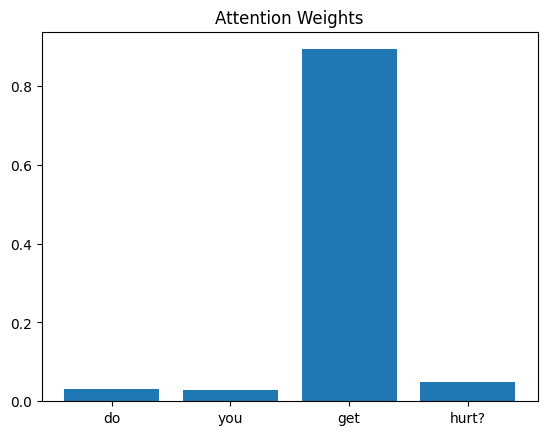

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [7]:
# Helper: returns the words of a question, their attention weights and the predicted answer
def get_attention(question):
    sequence = tokenizer.texts_to_sequences([question.lower()])   # same preprocessing as Step 3
    words = [tokenizer.index_word[i] for i in sequence[0]]
    with torch.no_grad():
        prediction, weights = model(torch.tensor(sequence))
    answer = df[df["answer_id"] == prediction.argmax(1).item()]["answer"].iloc[0]
    return words, weights[0].tolist(), answer

def plot_attention(question, ax):
    words, weights, answer = get_attention(question)
    bars = ax.bar(range(len(words)), weights, color="lightsteelblue")
    bars[weights.index(max(weights))].set_color("crimson")       # the word with the highest attention
    ax.set_xticks(range(len(words)), words, rotation=30)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Attention weight")
    ax.set_title(f'"{question}"\nPredicted answer: {answer}', fontsize=10)

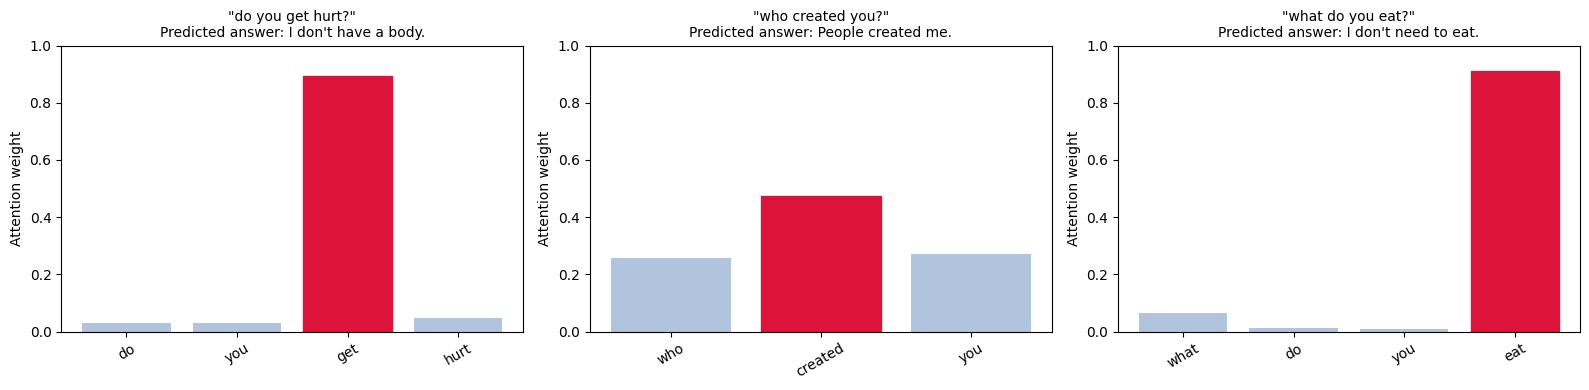

Question: do you get hurt?
   Weights: do=0.03, you=0.03, get=0.89, hurt=0.05
   Highest attention: 'get' (0.89)

Question: who created you?
   Weights: who=0.26, created=0.47, you=0.27
   Highest attention: 'created' (0.47)

Question: what do you eat?
   Weights: what=0.07, do=0.01, you=0.01, eat=0.91
   Highest attention: 'eat' (0.91)



In [8]:
# Three questions from the dataset (from three different answer groups)
task1_questions = [df["question"][0], df["question"][48], df["question"][108]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for question, ax in zip(task1_questions, axes):
    plot_attention(question, ax)
plt.tight_layout()
plt.show()

# The word with the highest attention weight in each question
for question in task1_questions:
    words, weights, answer = get_attention(question)
    print(f"Question: {question}")
    print("   Weights:", ", ".join(f"{w}={a:.2f}" for w, a in zip(words, weights)))
    print(f"   Highest attention: '{words[weights.index(max(weights))]}' ({max(weights):.2f})\n")

**Result:**

| Question | Predicted answer | Highest attention |
|---|---|---|
| *do you get hurt?* | I don't have a body. | **get** (0.89) |
| *who created you?* | People created me. | **created** (0.47) |
| *what do you eat?* | I don't need to eat. | **eat** (0.91) |

**Do the words with the highest attention weights appear important for understanding the question?**

**Mostly yes.** The model gives little attention to common words like *do*, *you*, *what*, *who*, which appear in almost every question and do not help to choose the answer. It focuses on the word that tells the topic:

- In *"what do you eat?"* almost all the attention (0.91) is on **eat**, the key word of the question. In the dataset *eat* appears only in questions about food (answer group 7).
- In *"who created you?"* the highest weight is on **created**, the important word, but the attention is more spread out (*who* 0.26, *you* 0.27), because *"who ... you"* is also a typical pattern of the questions about the creator.
- In *"do you get hurt?"* the highest weight is on **get** (0.89) and not on *hurt* (0.05), which looks less logical at first. The reason is that the attention is computed on the **RNN outputs**, not on the words alone. The RNN reads from left to right, so the output at *get* already contains the information *"do you get"*. In the dataset this pattern appears in *"do you get hurt?"*, *"do you get tired?"* and *"do you ever get hurt?"*, all in the same answer group (*I don't have a body*), so it is enough for the model to choose the answer.

So attention shows **which positions the model used to make the decision**. These are usually the important words, but because each RNN output also contains the previous words, the highest weight can be on a word that is not the most important one for a human.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

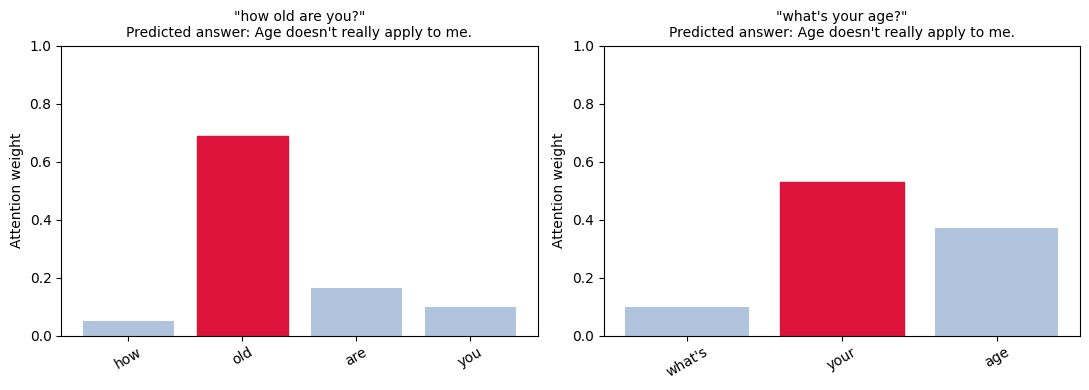

Question: how old are you?  ->  Predicted answer: Age doesn't really apply to me.
   Weights: how=0.05, old=0.69, are=0.16, you=0.10
   Highest attention: 'old' (0.69)

Question: what's your age?  ->  Predicted answer: Age doesn't really apply to me.
   Weights: what's=0.10, your=0.53, age=0.37
   Highest attention: 'your' (0.53)



In [9]:
# Two questions with the same meaning but different wording (both from answer group 1: age)
q1 = df["question"][24]
q2 = df["question"][20]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_attention(q1, axes[0])
plot_attention(q2, axes[1])
plt.tight_layout()
plt.show()

for question in [q1, q2]:
    words, weights, answer = get_attention(question)
    print(f"Question: {question}  ->  Predicted answer: {answer}")
    print("   Weights:", ", ".join(f"{w}={a:.2f}" for w, a in zip(words, weights)))
    print(f"   Highest attention: '{words[weights.index(max(weights))]}' ({max(weights):.2f})\n")

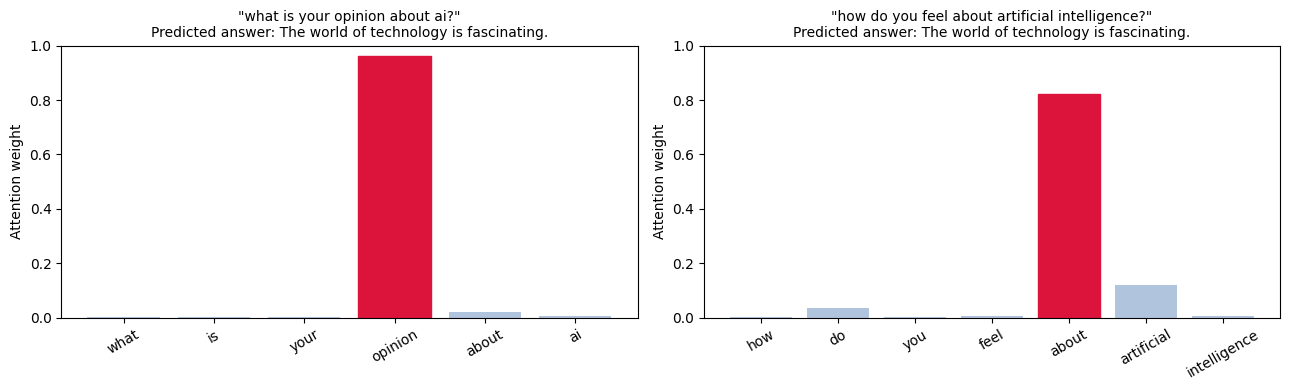

Question: what is your opinion about ai?  ->  Predicted answer: The world of technology is fascinating.
   Weights: what=0.01, is=0.00, your=0.00, opinion=0.96, about=0.02, ai=0.01
   Highest attention: 'opinion' (0.96)

Question: how do you feel about artificial intelligence?  ->  Predicted answer: The world of technology is fascinating.
   Weights: how=0.00, do=0.04, you=0.01, feel=0.01, about=0.82, artificial=0.12, intelligence=0.01
   Highest attention: 'about' (0.82)



In [10]:
# One more pair to check the observation (both from answer group 9: technology)
q3 = df["question"][128]
q4 = df["question"][126]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_attention(q3, axes[0])
plot_attention(q4, axes[1])
plt.tight_layout()
plt.show()

for question in [q3, q4]:
    words, weights, answer = get_attention(question)
    print(f"Question: {question}  ->  Predicted answer: {answer}")
    print("   Weights:", ", ".join(f"{w}={a:.2f}" for w, a in zip(words, weights)))
    print(f"   Highest attention: '{words[weights.index(max(weights))]}' ({max(weights):.2f})\n")

**Result:**

| Question | Predicted answer | Highest attention |
|---|---|---|
| *how old are you?* | Age doesn't really apply to me. | **old** (0.69) |
| *what's your age?* | Age doesn't really apply to me. | **your** (0.53), then **age** (0.37) |
| *what is your opinion about ai?* | The world of technology is fascinating. | **opinion** (0.96) |
| *how do you feel about artificial intelligence?* | The world of technology is fascinating. | **about** (0.82), then **artificial** (0.12) |

**Does the model focus on similar or different words when processing questions with similar meanings?**

The model gives the **same (correct) answer** to both questions of each pair, but it focuses on **different words**:

- In the age pair, it focuses on **old** in the first question and on **your** + **age** in the second one. *old* and *age* have the same meaning, but they are different words, so the model learned each of them separately. In the second question the attention is split: the output at *your* already contains *"what's your"*, and *age* gets the second highest weight.
- In the technology pair, it focuses on **opinion** in the first question and on **about** in the second one. *"how do you feel about ..."* appears many times in the technology group, so the output at *about* (which contains *"how do you feel about"*) is enough to recognize the topic.

**What does this suggest about how attention works?**

- Attention does **not understand meaning** like a human. It learns from the training data which positions help to choose the correct answer. Two questions with the same meaning can be solved by looking at different words.
- The model has small embeddings trained only on 168 questions, so it does not know that *old* and *age* or *AI* and *artificial intelligence* are similar. It only learns the words and patterns that are useful in this dataset.
- Because the attention is applied to the RNN outputs, a weight on one word also includes the words before it. So a high weight on a small word like *your* or *about* actually means *"the question so far"* (e.g. *"how do you feel about"*).
- Attention is still useful: it shows **why** the model chose an answer and helps to find what the model really learned.

__________________________________________________________________________________________

# What I Learned from Lab 11

In this lab I learned about **attention**, a mechanism that lets a neural network focus more on the important parts of the input when it makes a prediction.

### The RNN with Attention
- **Embedding** converts each word number into a vector, the **RNN** reads the words one by one and produces an output for every word, the **attention** layer gives each output a score, and `softmax` converts the scores into weights that sum to 1.
- The weighted sum of the RNN outputs is a single vector for the question, and the **output layer** chooses one of the 12 answers.
- The attention weights can be plotted as a bar chart to see which words the model used.

### Correcting the Code
- `nn.RNN` uses the shape *(words, batch, features)* by default, so `batch_first=True` is needed when the input is *(questions, words)*. Without it the RNN reads across the questions and the attention weights are wrong.
- The padding zeros must not get attention, so their scores are set to `-inf` before the softmax.
- `optimizer.zero_grad()` must be called in every epoch, otherwise PyTorch adds the new gradients to the old ones.
- After the fixes the model reaches **98.8 %** training accuracy after 50 epochs.

### Task 1 and Task 2
- The model usually gives the highest weight to the topic word of the question (*eat* 0.91, *opinion* 0.96, *old* 0.69) and very low weights to common words like *do* and *you*.
- Sometimes the highest weight is on a less important word (*get*, *your*, *about*), because the RNN output at that word also contains the words before it.
- Questions with the same meaning got the same correct answer, but the model focused on different words. Attention learns what is useful in the training data and does not understand meaning, but it is a useful way to explain the model's decisions.